In [15]:
import pandas as pd

In [16]:
df = pd.read_parquet('./data/clean_sms_spam_collection.parquet')

In [17]:
df.head(10)


,sms_message,label,embedding
0,"Go until jurong point, crazy.. Available only ...",0,"[0.0323555, 0.016009413, 0.06194499, -0.042135..."
1,Ok lar... Joking wif u oni...,0,"[0.08206976, -0.018639985, 0.026879955, -0.093..."
2,Free entry in 2 a wkly comp to win FA Cup fina...,1,"[0.094782084, -0.01949946, 0.01407177, -0.0518..."
3,U dun say so early hor... U c already then say...,0,"[0.07993865, -0.022020226, 0.020707738, -0.054..."
4,"Nah I don't think he goes to usf, he lives aro...",0,"[0.06651712, 0.044909604, 0.010687282, -0.0353..."
5,FreeMsg Hey there darling it's been 3 week's n...,1,"[0.056607906, -0.021531032, -0.012310791, -0.0..."
6,Even my brother is not like to speak with me. ...,0,"[0.007443019, 0.07728682, 0.020719808, -0.1012..."
7,As per your request 'Melle Melle (Oru Minnamin...,0,"[0.03562765, -0.022721196, 0.017454114, -0.036..."
8,WINNER!! As a valued network customer you have...,1,"[0.058819037, -0.0017373714, 0.03937096, -0.01..."
9,Had your mobile 11 months or more? U R entitle...,1,"[0.0233127, -0.005538072, -0.022738425, -0.010..."


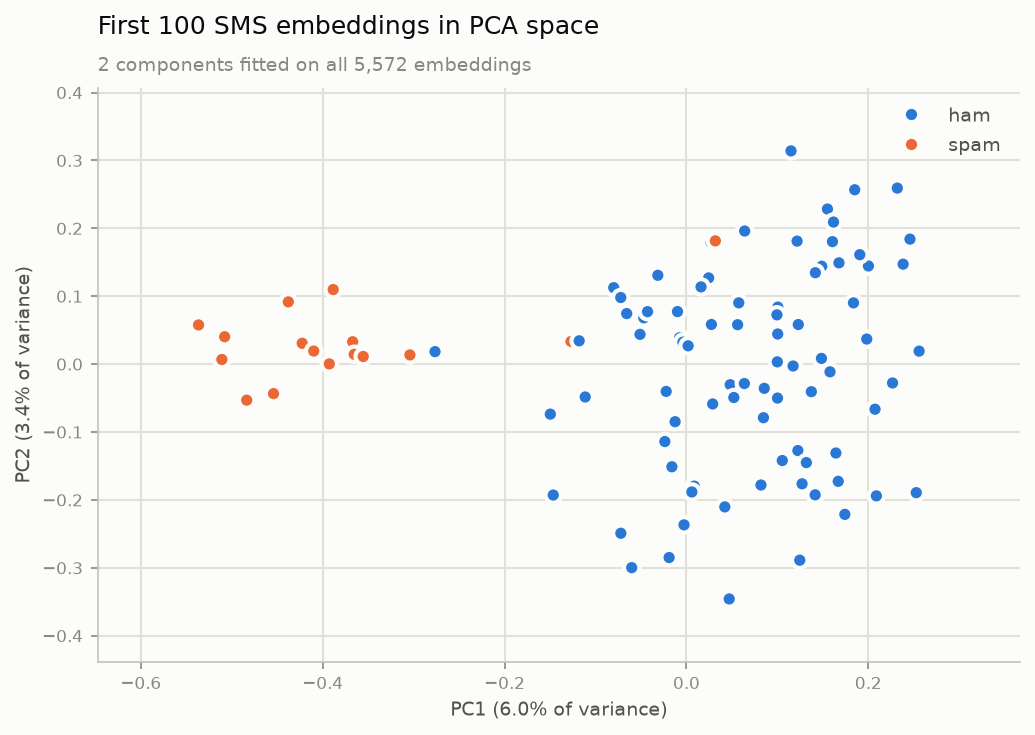

,pc1,pc2,class,sms_message
0,-0.111308,-0.048370,ham,"Go until jurong point, crazy.. Available only…"
1,0.100534,0.084020,ham,Ok lar... Joking wif u oni...…
2,-0.392754,0.000363,spam,Free entry in 2 a wkly comp to win FA Cup fin…
3,0.117323,-0.002747,ham,U dun say so early hor... U c already then sa…
4,0.137363,-0.040585,ham,"Nah I don't think he goes to usf, he lives ar…"
...,...,...,...,...
95,-0.388433,0.109858,spam,Your free ringtone is waiting to be collected…
96,0.001866,0.026976,ham,Watching telugu movie..wat abt u?…
97,0.052126,-0.049176,ham,i see. When we finish we have loads of loans …
98,0.208899,-0.194061,ham,Hi. Wk been ok - on hols now! Yes on for a bi…


In [18]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.decomposition import PCA

N = 100

# Fit on every embedding so the axes are the dataset's real principal axes,
# then plot only the first N rows
X = np.stack(df['embedding'].to_numpy())
pca = PCA(n_components=2)
coords = pca.fit_transform(X)
ev = pca.explained_variance_ratio_

plot_df = pd.DataFrame({
    'pc1': coords[:N, 0],
    'pc2': coords[:N, 1],
    'class': df['label'].head(N).map({0: 'ham', 1: 'spam'}),
})

SURFACE, GRID, AXIS = '#fcfcfb', '#e1e0d9', '#c3c2b7'
INK, INK_2, MUTED = '#0b0b0b', '#52514e', '#898781'
PALETTE = {'ham': '#2a78d6', 'spam': '#eb6834'}

# Thin the dots and drop the per-row labels once the plot gets crowded -- a
# label on every one of 100 points collides into noise and goes unread
DOT = 110 if N <= 20 else 55
LABEL_ROWS = N <= 20

fig, ax = plt.subplots(figsize=(7, 5), dpi=150)
fig.patch.set_facecolor(SURFACE)
ax.set_facecolor(SURFACE)

# linewidth/edgecolor = 2px surface ring, so overlapping dots stay readable
sns.scatterplot(data=plot_df, x='pc1', y='pc2', hue='class', palette=PALETTE,
                hue_order=['ham', 'spam'], s=DOT, linewidth=2,
                edgecolor=SURFACE, zorder=3, ax=ax)

# Row index beside each dot, in muted ink rather than the series color
if LABEL_ROWS:
    for i, r in plot_df.iterrows():
        ax.annotate(str(i), (r['pc1'], r['pc2']), textcoords='offset points',
                    xytext=(9, 0), va='center', fontsize=8, color=MUTED)

ax.grid(True, color=GRID, linewidth=1, linestyle='-')
ax.set_axisbelow(True)
ax.margins(0.14)
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)
for s in ('left', 'bottom'):
    ax.spines[s].set_color(AXIS)
ax.tick_params(colors=MUTED, labelsize=8)

ax.set_xlabel(f'PC1 ({ev[0]:.1%} of variance)', color=INK_2, fontsize=9)
ax.set_ylabel(f'PC2 ({ev[1]:.1%} of variance)', color=INK_2, fontsize=9)
ax.set_title(f'First {N} SMS embeddings in PCA space', color=INK, fontsize=12,
             loc='left', pad=26)
ax.text(0, 1.03, f'2 components fitted on all {len(df):,} embeddings',
        transform=ax.transAxes, color=MUTED, fontsize=9)

leg = ax.legend(title=None, frameon=False, loc='best')
for t in leg.get_texts():
    t.set_color(INK_2)
    t.set_fontsize(9)

fig.tight_layout()
plt.show()

# Table view: the same values as text, so nothing is readable only from the plot
plot_df.assign(sms_message=df['sms_message'].head(N).str.slice(0, 45) + '…')

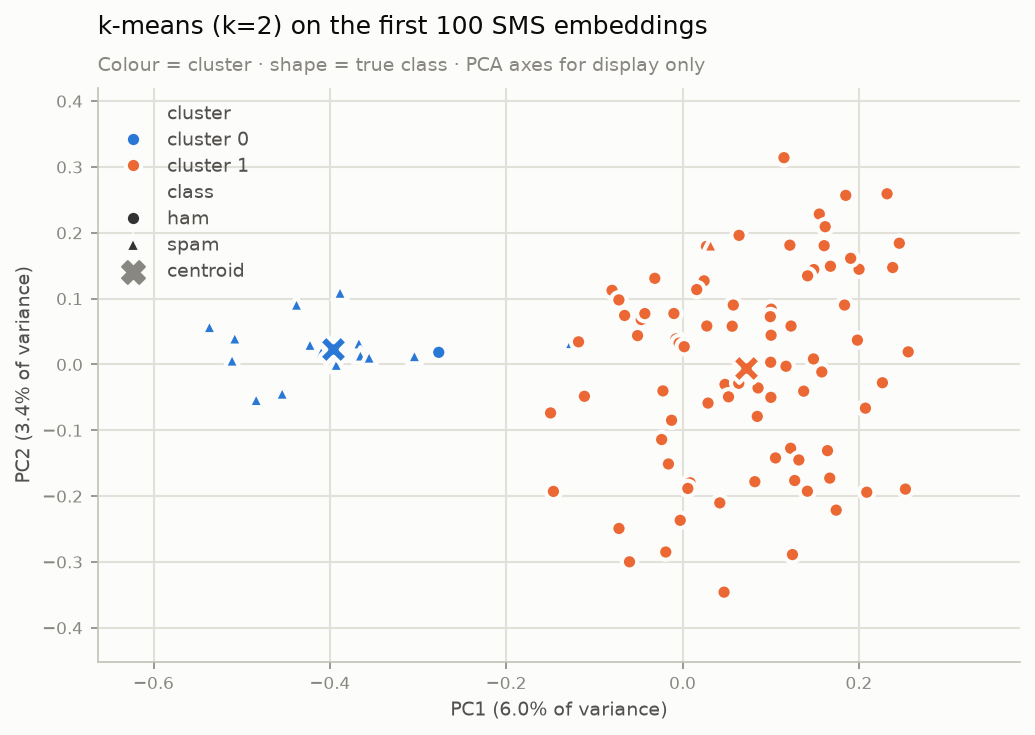

adjusted Rand index vs true labels: 0.854


class,ham,spam
cluster,,
cluster 0,1,15
cluster 1,82,2


In [19]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

K = 2

# Cluster in the full 1024-d embedding space, not on the 2 PCA components
km = KMeans(n_clusters=K, n_init=10, random_state=0)
cluster = km.fit_predict(X[:N])

cl_df = pd.DataFrame({
    'pc1': coords[:N, 0],
    'pc2': coords[:N, 1],
    'cluster': [f'cluster {c}' for c in cluster],
    'class': df['label'].head(N).map({0: 'ham', 1: 'spam'}),
})

CLUSTER_PALETTE = {'cluster 0': '#2a78d6', 'cluster 1': '#eb6834'}
CLUSTER_ORDER = [f'cluster {c}' for c in range(K)]
MARKERS = {'ham': 'o', 'spam': '^'}

fig, ax = plt.subplots(figsize=(7, 5), dpi=150)
fig.patch.set_facecolor(SURFACE)
ax.set_facecolor(SURFACE)

# hue_order keeps colour tied to the cluster id, not to order of appearance
sns.scatterplot(data=cl_df, x='pc1', y='pc2', hue='cluster', style='class',
                palette=CLUSTER_PALETTE, hue_order=CLUSTER_ORDER,
                markers=MARKERS, style_order=['ham', 'spam'],
                s=DOT, linewidth=2, edgecolor=SURFACE, zorder=3, ax=ax)

# PCA is affine, so projecting a 1024-d centroid lands exactly on the centroid
# of its projected points. Drawn on top; the surface ring keeps it separate
# from the cloud underneath.
cen = pca.transform(km.cluster_centers_)
for c in range(K):
    ax.scatter(*cen[c], marker='X', s=190, color=CLUSTER_PALETTE[f'cluster {c}'],
               edgecolor=SURFACE, linewidth=2, zorder=5)
ax.scatter([], [], marker='X', s=120, color=MUTED, label='centroid')

if LABEL_ROWS:
    for i, r in cl_df.iterrows():
        ax.annotate(str(i), (r['pc1'], r['pc2']), textcoords='offset points',
                    xytext=(9, 0), va='center', fontsize=8, color=MUTED)

ax.grid(True, color=GRID, linewidth=1, linestyle='-')
ax.set_axisbelow(True)
ax.margins(0.16)
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)
for s in ('left', 'bottom'):
    ax.spines[s].set_color(AXIS)
ax.tick_params(colors=MUTED, labelsize=8)

ax.set_xlabel(f'PC1 ({ev[0]:.1%} of variance)', color=INK_2, fontsize=9)
ax.set_ylabel(f'PC2 ({ev[1]:.1%} of variance)', color=INK_2, fontsize=9)
ax.set_title(f'k-means (k={K}) on the first {N} SMS embeddings', color=INK,
             fontsize=12, loc='left', pad=26)
ax.text(0, 1.03, 'Colour = cluster · shape = true class · PCA axes for display only',
        transform=ax.transAxes, color=MUTED, fontsize=9)

leg = ax.legend(frameon=False, loc='best', fontsize=9, labelspacing=0.4)
for t in leg.get_texts():
    t.set_color(INK_2)

fig.tight_layout()
plt.show()

# Do the clusters actually correspond to ham/spam? Cluster ids are arbitrary,
# so read the crosstab, not the id numbers.
print(f'adjusted Rand index vs true labels: '
      f'{adjusted_rand_score(df["label"].head(N), cluster):.3f}')
pd.crosstab(cl_df['cluster'], cl_df['class'])

In [20]:
SAMPLES = 10

# cl_df is indexed 0..N-1, so the message column aligns straight onto it
sample_src = cl_df.assign(sms_message=df['sms_message'].head(N))

for name in CLUSTER_ORDER:
    grp = sample_src[sample_src['cluster'] == name]
    mix = ' / '.join(f'{v} {k}' for k, v in grp['class'].value_counts().items())
    print(f'{name} — {len(grp)} records ({mix})')
    for i, r in grp.sample(min(SAMPLES, len(grp)),
                           random_state=0).sort_index().iterrows():
        msg = ' '.join(r['sms_message'].split())  # collapse embedded newlines
        print(f'  {i:>4}  {r["class"]:<4}  {msg[:88]}{"…" if len(msg) > 88 else ""}')
    print()

cluster 0 — 16 records (15 spam / 1 ham)
     7  ham   As per your request 'Melle Melle (Oru Minnaminunginte Nurungu Vettam)' has been set as y…
     8  spam  WINNER!! As a valued network customer you have been selected to receivea £900 prize rewa…
    11  spam  SIX chances to win CASH! From 100 to 20,000 pounds txt> CSH11 and send to 87575. Cost 15…
    15  spam  XXXMobileMovieClub: To use your credit, click the WAP link in the next txt message or cl…
    19  spam  England v Macedonia - dont miss the goals/team news. Txt ur national team to 87077 eg EN…
    34  spam  Thanks for your subscription to Ringtone UK your mobile will be charged £5/month Please …
    42  spam  07732584351 - Rodger Burns - MSG = We tried to call you re your reply to our sms for a f…
    54  spam  SMS. ac Sptv: The New Jersey Devils and the Detroit Red Wings play Ice Hockey. Correct o…
    67  spam  Urgent UR awarded a complimentary trip to EuroDisinc Trav, Aco&Entry41 Or £1000. To clai…
    93  spam  Please ca

In [21]:
# km was fit on the first N rows only; predict() applies those same two
# centroids to every row, so the column comes out gap-free and castable to int64.
# cluster 0 is the spam-heavy one, so 0 -> 1 / 1 -> 0 lines the column up with
# the existing 'label' convention (1 = spam).
df['cluster_label'] = (km.predict(X) == 0).astype('int64')

with pd.option_context('display.max_rows', 150):
    display(df.head(150))

,sms_message,label,embedding,cluster_label
0,"Go until jurong point, crazy.. Available only ...",0,"[0.0323555, 0.016009413, 0.06194499, -0.042135...",0
1,Ok lar... Joking wif u oni...,0,"[0.08206976, -0.018639985, 0.026879955, -0.093...",0
2,Free entry in 2 a wkly comp to win FA Cup fina...,1,"[0.094782084, -0.01949946, 0.01407177, -0.0518...",1
3,U dun say so early hor... U c already then say...,0,"[0.07993865, -0.022020226, 0.020707738, -0.054...",0
4,"Nah I don't think he goes to usf, he lives aro...",0,"[0.06651712, 0.044909604, 0.010687282, -0.0353...",0
5,FreeMsg Hey there darling it's been 3 week's n...,1,"[0.056607906, -0.021531032, -0.012310791, -0.0...",0
6,Even my brother is not like to speak with me. ...,0,"[0.007443019, 0.07728682, 0.020719808, -0.1012...",0
7,As per your request 'Melle Melle (Oru Minnamin...,0,"[0.03562765, -0.022721196, 0.017454114, -0.036...",1
8,WINNER!! As a valued network customer you have...,1,"[0.058819037, -0.0017373714, 0.03937096, -0.01...",1
9,Had your mobile 11 months or more? U R entitle...,1,"[0.0233127, -0.005538072, -0.022738425, -0.010...",1


In [22]:
from sklearn.metrics import accuracy_score

# Unsupervised clustering scored against the ground truth: the mapping
# cluster 0 -> 1 / cluster 1 -> 0 was chosen by hand, so this only means
# anything because that orientation is the sensible one.
acc = accuracy_score(df['label'], df['cluster_label'])
print(f'accuracy: {acc:.4f}  ({(df["label"] == df["cluster_label"]).sum():,} '
      f'of {len(df):,} correct)')

accuracy: 0.9810  (5,466 of 5,572 correct)


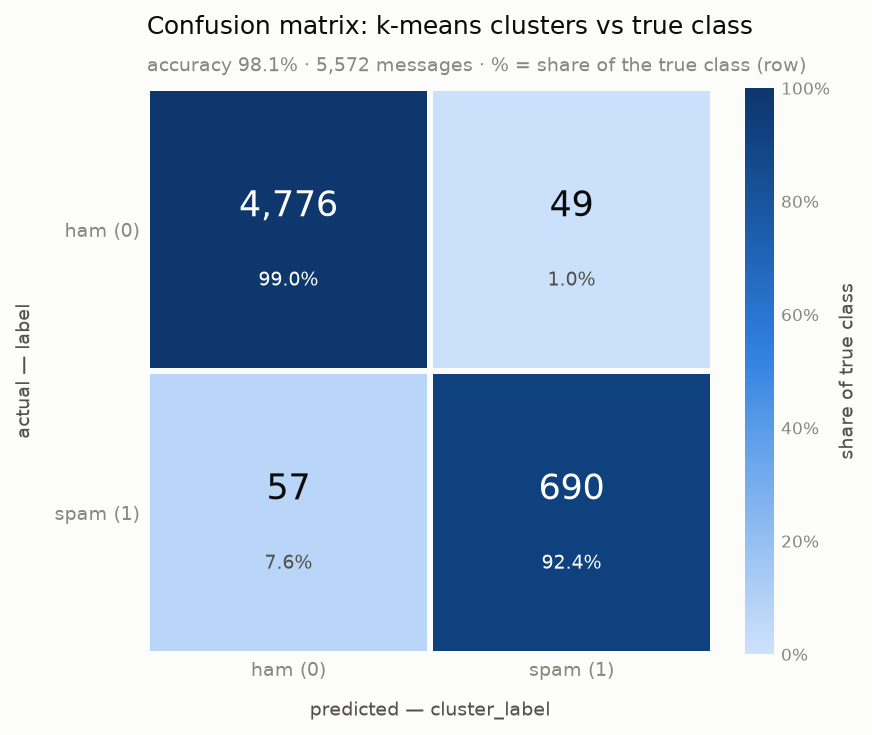

predicted,0,1,All
actual,,,
0,4776,49,4825
1,57,690,747
All,4833,739,5572


In [23]:
import matplotlib.ticker as mticker
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import confusion_matrix

CLASSES = ['ham (0)', 'spam (1)']

cm = confusion_matrix(df['label'], df['cluster_label'])
# Row-normalise for colour: the classes are ~7:1 imbalanced, so raw counts would
# paint three of the four cells the same near-white and hide both error cells.
cm_share = cm / cm.sum(axis=1, keepdims=True)

# Magnitude on a grid -> sequential encoding: one hue, light to dark, never a
# rainbow. Blue ramp, steps 100..700.
BLUE_RAMP = ['#cde2fb', '#b7d3f6', '#9ec5f4', '#86b6ef', '#6da7ec', '#5598e7',
             '#3987e5', '#2a78d6', '#256abf', '#1c5cab', '#184f95', '#104281',
             '#0d366b']
cmap = LinearSegmentedColormap.from_list('blue_sequential', BLUE_RAMP)

fig, ax = plt.subplots(figsize=(6.4, 5), dpi=150)
fig.patch.set_facecolor(SURFACE)
ax.set_facecolor(SURFACE)

# edgecolor in the surface colour is the 2px gap between cells -- neighbours are
# separated by negative space, not by a border drawn around each one
mesh = ax.pcolormesh(np.arange(3), np.arange(3), cm_share, cmap=cmap,
                     vmin=0, vmax=1, edgecolors=SURFACE, linewidth=2)
ax.invert_yaxis()
ax.set_aspect('equal')

# Count + row share in each cell. Four cells, so the grid is its own table; ink
# or white is picked per cell from the fill's luminance so text always clears it.
for i in range(2):
    for j in range(2):
        r, g, b, _ = cmap(cm_share[i, j])
        light_fill = 0.2126 * r + 0.7152 * g + 0.0722 * b > 0.55
        ax.text(j + 0.5, i + 0.42, f'{cm[i, j]:,}', ha='center', va='center',
                fontsize=17, color=INK if light_fill else '#ffffff')
        ax.text(j + 0.5, i + 0.68, f'{cm_share[i, j]:.1%}', ha='center',
                va='center', fontsize=9,
                color=INK_2 if light_fill else '#ffffff')

ax.set_xticks(np.arange(2) + 0.5, CLASSES)
ax.set_yticks(np.arange(2) + 0.5, CLASSES)
ax.tick_params(colors=MUTED, labelsize=9, length=0)
for s in ax.spines.values():
    s.set_visible(False)

ax.set_xlabel('predicted — cluster_label', color=INK_2, fontsize=9, labelpad=10)
ax.set_ylabel('actual — label', color=INK_2, fontsize=9, labelpad=10)
ax.set_title('Confusion matrix: k-means clusters vs true class', color=INK,
             fontsize=12, loc='left', pad=26)
ax.text(0, 1.03, f'accuracy {acc:.1%} · {len(df):,} messages · % = share of the '
                 f'true class (row)', transform=ax.transAxes, color=MUTED,
        fontsize=9)

# Scale legend for the continuous encoding
cb = fig.colorbar(mesh, ax=ax, fraction=0.045, pad=0.04)
cb.outline.set_visible(False)
cb.ax.tick_params(colors=MUTED, labelsize=8, length=0)
cb.ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
cb.set_label('share of true class', color=INK_2, fontsize=9)

fig.tight_layout()
plt.show()

# Table view: the same numbers as text, so nothing is readable only from colour
pd.crosstab(df['label'], df['cluster_label'],
            rownames=['actual'], colnames=['predicted'], margins=True)

In [24]:
df.to_parquet('./data/sms_training_data.parquet', index=False)